# ML 01 - Demand Forecasting for Inventory Planning

**Objective:** forecast monthly demand for the highest-volume SKUs of the Kaizen Analytics inventory dataset, compare classical forecasting methods under a strict time-based evaluation, and translate forecast error into **safety-stock** requirements.

**Method comparison:** Naive, Seasonal Naive, Moving Average (3 and 6 months), Simple Exponential Smoothing, Damped Holt, Holt-Winters, auto-selected ETS and auto-selected SARIMA (all `statsmodels`).

**Validation:** (1) time-based hold-out (last 6 months), (2) expanding-window rolling-origin evaluation (no random splitting, no look-ahead).

In [1]:
import warnings, os, time
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd

import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from joblib import Parallel, delayed
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.simplefilter("ignore")          # statsmodels re-enables ConvergenceWarning on import
os.environ["PYTHONWARNINGS"] = "ignore"  # inherited by joblib worker processes

sns.set_theme(style="whitegrid")
OUT = Path(".")
CANDIDATES = [Path("dataset_kaizen analytics.xlsx"),
              Path("../../python/02_inventory_optimization/dataset_kaizen analytics.xlsx")]
XLSX = next(p for p in CANDIDATES if p.exists())
print("Using dataset:", XLSX)

Using dataset: ..\..\python\02_inventory_optimization\dataset_kaizen analytics.xlsx


## 1. Data loading and validation
The sales sheet has 5 empty trailing columns and a trailing space in the `Order Number ` header; both are cleaned.

In [2]:
sales = pd.read_excel(XLSX, sheet_name="Sales Data").iloc[:, :8]
sales.columns = sales.columns.str.strip()
inv = pd.read_excel(XLSX, sheet_name="Inventory Control")

print("Sales rows:", len(sales), "| SKUs:", sales["SKU ID"].nunique())
print("Date range:", sales["Order Date"].min().date(), "->", sales["Order Date"].max().date())
print("Missing values:", int(sales.isna().sum().sum()), "| duplicated order numbers:", int(sales["Order Number"].duplicated().sum()))
print("Non-positive quantities:", int((sales["Order Quantity"] <= 0).sum()))
print("SKU IDs unique in inventory sheet:", inv["SKU ID"].is_unique, "| SKUs in sales missing from inventory:", len(set(sales["SKU ID"]) - set(inv["SKU ID"])))
sales["month"] = sales["Order Date"].dt.to_period("M").dt.to_timestamp()
monthly_all = sales.groupby("month").agg(orders=("SKU ID", "size"), active_skus=("SKU ID", "nunique"),
                                         units=("Order Quantity", "sum"))
monthly_all.T.round(0).astype(int).iloc[:, [0, 1, 11, 12, 23, 24, 25, 30]]

Sales rows: 33919 | SKUs: 290
Date range: 2021-01-01 -> 2023-07-30
Missing values: 0 | duplicated order numbers: 0
Non-positive quantities: 0
SKU IDs unique in inventory sheet: True | SKUs in sales missing from inventory: 0


month,2021-01-01,2021-02-01,2021-12-01,2022-01-01,2022-12-01,2023-01-01,2023-02-01,2023-07-01
orders,1330,1204,1333,1333,1333,372,336,360
active_skus,209,203,244,244,248,173,161,175
units,394060,378936,667707,736258,648064,160182,148405,135972


## 2. Series construction and the 2023 structural break
Demand = sum of `Order Quantity` per SKU per calendar month (31 months, Jan-2021 to Jul-2023; zero-filled where a SKU had no orders). I model the **top-10 SKUs by total volume** plus the **total across all SKUs**.

Important: the number of orders per month falls from about 1,300 to about 360 from January 2023. This is a level shift in the data (not a seasonal pattern) and every method has to cope with it.

Top-10 SKUs cover 69.3% of all units ordered
Months: 31 | zero-demand months in top-10 series: {'2391CA': 5, '2418CA': 2, '2473CA': 7, '2371CA': 4, '3533CA': 1, '1244AA': 4, '3619CA': 0, '2458CA': 1, '3512AA': 2, '1077CA': 3}


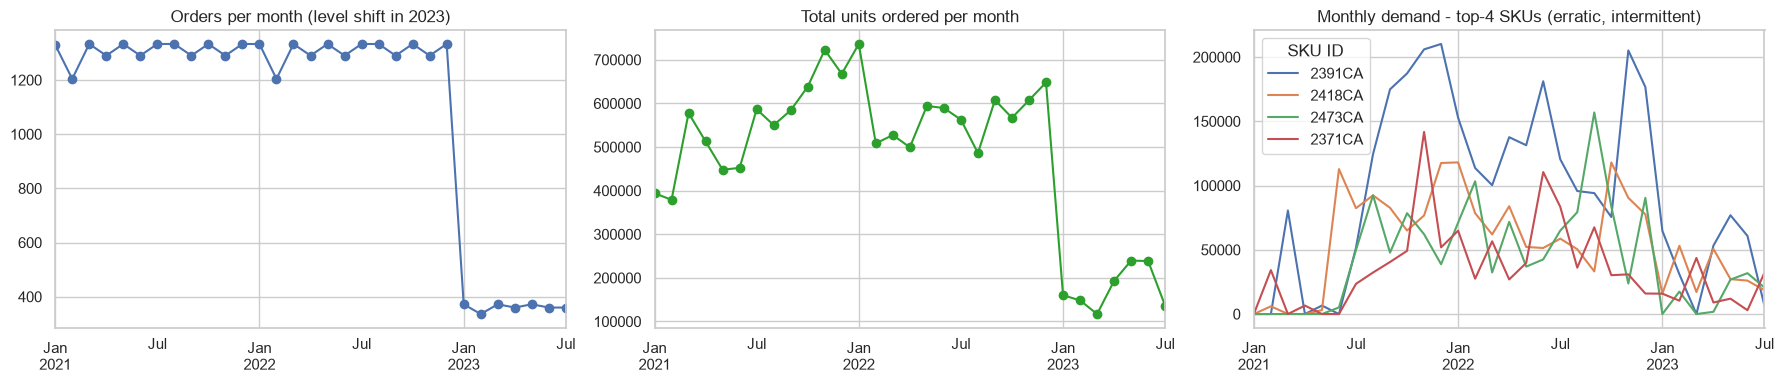

In [3]:
months = pd.date_range("2021-01-01", "2023-07-01", freq="MS")
pivot = (sales.groupby(["SKU ID", "month"])["Order Quantity"].sum().unstack(fill_value=0)
              .reindex(columns=months, fill_value=0))
top10 = pivot.sum(axis=1).sort_values(ascending=False).head(10).index.tolist()
series = {sku: pivot.loc[sku].values.astype(float) for sku in top10}
series["TOTAL"] = pivot.sum(axis=0).values.astype(float)
print("Top-10 SKUs cover %.1f%% of all units ordered" % (100 * pivot.loc[top10].values.sum() / pivot.values.sum()))
print("Months:", len(months), "| zero-demand months in top-10 series:",
      {k: int((v == 0).sum()) for k, v in series.items() if k != "TOTAL"})

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
monthly_all["orders"].plot(ax=ax[0], marker="o"); ax[0].set_title("Orders per month (level shift in 2023)")
monthly_all["units"].plot(ax=ax[1], marker="o", color="tab:green"); ax[1].set_title("Total units ordered per month")
pivot.loc[top10[:4]].T.plot(ax=ax[2]); ax[2].set_title("Monthly demand - top-4 SKUs (erratic, intermittent)")
for a in ax: a.set_xlabel("")
plt.tight_layout(); plt.savefig(OUT / "01_demand_structure.png", dpi=130); plt.show()

## 3. Forecasting methods
All forecasts are made from the training window only and floored at zero.

| Model | Notes |
|---|---|
| Naive | last observed month |
| Seasonal naive | same month last year (needs >= 12 months) |
| MA(3), MA(6) | mean of the last 3 / 6 months |
| SES | simple exponential smoothing, alpha optimised |
| Damped Holt | additive damped trend |
| Holt-Winters | additive damped trend + additive seasonality (period 12) |
| ETS (auto) | `ETSModel` with additive errors; best of {none, damped trend} x {no season, additive season} by AICc |
| SARIMA (auto) | best of (1,0,0), (1,0,1), (0,1,1) x {no seasonal part, (1,0,0,12)} by AICc |

**Rule:** a seasonal component is only estimated when the training window has **>= 24 observations** (two full seasonal cycles). For shorter windows the seasonal models are marked as not available (NaN) rather than silently falling back to a different method.

In [4]:
H_MAX = 3
MODELS = ["Naive", "Seasonal naive", "MA(3)", "MA(6)", "SES", "Damped Holt", "Holt-Winters", "ETS (auto)", "SARIMA (auto)"]

def aicc(res, n):
    k = len(res.params)
    return res.aic + 2 * k * (k + 1) / max(n - k - 1, 1)

def forecast(name, y, h):
    n = len(y)
    if name == "Naive":
        f = np.repeat(y[-1], h)
    elif name == "Seasonal naive":
        if n < 12: return np.full(h, np.nan)
        f = np.array([y[n - 12 + (i % 12)] for i in range(h)])
    elif name == "MA(3)":
        f = np.repeat(y[-3:].mean(), h)
    elif name == "MA(6)":
        f = np.repeat(y[-6:].mean(), h)
    elif name == "SES":
        f = SimpleExpSmoothing(y, initialization_method="estimated").fit().forecast(h)
    elif name == "Damped Holt":
        f = ExponentialSmoothing(y, trend="add", damped_trend=True, initialization_method="estimated").fit().forecast(h)
    elif name == "Holt-Winters":
        if n < 24: return np.full(h, np.nan)
        f = ExponentialSmoothing(y, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12,
                                 initialization_method="estimated").fit().forecast(h)
    elif name == "ETS (auto)":
        best, best_ic = None, np.inf
        for trend, damped, seas in [(None, False, None), ("add", True, None), (None, False, "add"), ("add", True, "add")]:
            if seas and n < 24: continue
            try:
                r = ETSModel(y, error="add", trend=trend, damped_trend=damped, seasonal=seas,
                             seasonal_periods=12 if seas else None, initialization_method="estimated").fit(disp=False)
                ic = aicc(r, n)
                if np.isfinite(ic) and ic < best_ic: best, best_ic = r, ic
            except Exception:
                continue
        if best is None: return np.full(h, np.nan)
        f = best.forecast(h)
    elif name == "SARIMA (auto)":
        best, best_ic = None, np.inf
        for order in [(1, 0, 0), (1, 0, 1), (0, 1, 1)]:
            for seas in [(0, 0, 0, 0), (1, 0, 0, 12)]:
                if seas[3] and n < 24: continue
                try:
                    r = SARIMAX(y, order=order, seasonal_order=seas, trend="c" if order[1] == 0 else "n",
                                enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=100)
                    ic = aicc(r, n)
                    if np.isfinite(ic) and ic < best_ic: best, best_ic = r, ic
                except Exception:
                    continue
        if best is None: return np.full(h, np.nan)
        f = best.forecast(h)
    return np.maximum(np.asarray(f, dtype=float), 0)

# quick smoke test on the total series
for m in MODELS:
    print(f"{m:15s}", np.round(forecast(m, series["TOTAL"][:25], 3)))

Naive           [160182. 160182. 160182.]
Seasonal naive  [508250. 527473. 499312.]
MA(3)           [471817. 471817. 471817.]
MA(6)           [512707. 512707. 512707.]


SES             [462543. 462543. 462543.]
Damped Holt     [573287. 573397. 573485.]
Holt-Winters    [234292. 314597. 245985.]


ETS (auto)      [427725. 427725. 427725.]


SARIMA (auto)   [702260. 583307. 556103.]


## 4. Evaluation design
**Hold-out:** train on the first 25 months (Jan-2021 to Jan-2023), forecast the last 6 months (Feb-Jul 2023) in one shot (horizons 1-6). Nothing from the test window enters the fit.

**Rolling origin (expanding window):** origins at 12, 13, ..., 30 training months; each origin forecasts the next up to 3 months (truncated at the end of data). All forecasts use only data available at the origin. Model comparison uses the common origins with >= 24 training months so that every model is eligible.

**Second regime check (pre-break):** because the 2023 level shift dominates the errors of every trend/level-averaging method, I repeat both schemes using **only 2021-2022 (24 months, stable regime)**: hold-out = train 18 months -> forecast the last 6 months of 2022; rolling origins at 12-23 months. Seasonal models (>= 24 months rule) cannot be evaluated here, except seasonal naive.

**Metrics:** MAE, RMSE, **WAPE** = sum|error| / sum(actual) (robust to zeros, unlike MAPE), and bias = sum(forecast - actual) / sum(actual). With zero-demand months in several series, MAPE is undefined, so it is not used.

In [5]:
def run_series(key, y):
    warnings.simplefilter("ignore")
    rows = []
    n_tot = len(y)
    # rolling origin
    for n in range(12, n_tot):
        h = min(H_MAX, n_tot - n)
        for m in MODELS:
            f = forecast(m, y[:n], h)
            for i in range(h):
                rows.append((key, "rolling", m, n, i + 1, n + i, y[n + i], f[i]))
    # hold-out: fixed origin at 25 months, horizon 6
    for m in MODELS:
        f = forecast(m, y[:25], 6)
        for i in range(6):
            rows.append((key, "holdout", m, 25, i + 1, 25 + i, y[25 + i], f[i]))
    # regime A only (Jan-2021..Dec-2022, before the 2023 level shift): 24 months
    yp = y[:24]
    for n in range(12, 24):
        h = min(H_MAX, 24 - n)
        for m in MODELS:
            f = forecast(m, yp[:n], h)
            for i in range(h):
                rows.append((key, "pre_rolling", m, n, i + 1, n + i, yp[n + i], f[i]))
    for m in MODELS:
        f = forecast(m, yp[:18], 6)
        for i in range(6):
            rows.append((key, "pre_holdout", m, 18, i + 1, 18 + i, yp[18 + i], f[i]))
    return rows

t0 = time.time()
res = Parallel(n_jobs=-1)(delayed(run_series)(k, v) for k, v in series.items())
fc = pd.DataFrame([r for rr in res for r in rr],
                  columns=["series", "scheme", "model", "origin_n", "h", "t_idx", "actual", "forecast"])
fc["month"] = months[fc["t_idx"].values]
fc["error"] = fc["forecast"] - fc["actual"]
print("Done in %.0fs | forecast rows: %d | NaN forecasts (ineligible seasonal models): %d" % (time.time() - t0, len(fc), fc["forecast"].isna().sum()))
fc.to_csv(OUT / "forecasts_all_origins.csv", index=False)

Done in 27s | forecast rows: 9801 | NaN forecasts (ineligible seasonal models): 825


In [6]:
def metrics(g):
    g = g.dropna(subset=["forecast"])
    e = g["error"]; a = g["actual"]
    return pd.Series({"n": len(g), "MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()),
                      "WAPE": e.abs().sum() / a.sum(), "Bias": e.sum() / a.sum()})

def summarize(df):
    per = df.groupby(["series", "model"]).apply(metrics).reset_index()
    sku = per[per.series != "TOTAL"].groupby("model").agg(WAPE_mean=("WAPE", "mean"), WAPE_median=("WAPE", "median"),
                                                          Bias_mean=("Bias", "mean"), n_per_series=("n", "mean"))
    tot = per[per.series == "TOTAL"].set_index("model")[["MAE", "RMSE", "WAPE", "Bias"]].add_prefix("TOTAL_")
    out = sku.join(tot).loc[MODELS]
    out["Rel. WAPE vs naive"] = out["WAPE_mean"] / out.loc["Naive", "WAPE_mean"]
    return per, out

hold = fc[fc.scheme == "holdout"]
per_hold, sum_hold = summarize(hold)
common = fc[(fc.scheme == "rolling") & (fc.origin_n >= 24)]
per_roll, sum_roll = summarize(common)
print("HOLD-OUT (train 25 months -> forecast Feb-Jul 2023), mean over top-10 SKUs of per-SKU WAPE")
display(sum_hold.round(3).sort_values("WAPE_mean"))
print("ROLLING ORIGIN (origins 24-30 months, horizon <= 3), same metric")
display(sum_roll.round(3).sort_values("WAPE_mean"))
pre_hold = fc[fc.scheme == "pre_holdout"]; pre_roll = fc[fc.scheme == "pre_rolling"]
per_pre_hold, sum_pre_hold = summarize(pre_hold)
per_pre_roll, sum_pre_roll = summarize(pre_roll)
print("PRE-BREAK REGIME (2021-2022 only) - HOLD-OUT (train 18 months -> forecast Jul-Dec 2022)")
display(sum_pre_hold.dropna(subset=["WAPE_mean"]).round(3).sort_values("WAPE_mean"))
print("PRE-BREAK REGIME - ROLLING ORIGIN (origins 12-23 months, horizon <= 3)")
display(sum_pre_roll.dropna(subset=["WAPE_mean"]).round(3).sort_values("WAPE_mean"))
sum_pre_hold.round(4).to_csv(OUT / "metrics_prebreak_holdout_summary.csv")
sum_pre_roll.round(4).to_csv(OUT / "metrics_prebreak_rolling_summary.csv")
per_hold.to_csv(OUT / "metrics_holdout_per_series.csv", index=False)
per_roll.to_csv(OUT / "metrics_rolling_per_series.csv", index=False)
sum_hold.round(4).to_csv(OUT / "metrics_holdout_summary.csv")
sum_roll.round(4).to_csv(OUT / "metrics_rolling_summary.csv")

HOLD-OUT (train 25 months -> forecast Feb-Jul 2023), mean over top-10 SKUs of per-SKU WAPE


,WAPE_mean,WAPE_median,Bias_mean,n_per_series,TOTAL_MAE,TOTAL_RMSE,TOTAL_WAPE,TOTAL_Bias,Rel. WAPE vs naive
model,,,,,,,,,
Naive,1.054,0.819,0.115,6.0,44968.826,51828.033,0.252,-0.104,1.000
Holt-Winters,3.035,2.200,2.432,6.0,84696.841,111786.033,0.474,0.474,2.879
MA(3),3.188,1.471,3.076,6.0,293039.478,297005.898,1.639,1.639,3.025
ETS (auto),3.205,1.531,3.090,6.0,248947.632,253604.596,1.393,1.393,3.041
Damped Holt,3.304,2.361,3.289,6.0,394721.886,397668.746,2.208,2.208,3.134
Seasonal naive,3.477,2.507,3.383,6.0,368105.971,370274.137,2.059,2.059,3.298
SES,3.583,1.713,3.474,6.0,283765.642,287859.874,1.587,1.587,3.399
SARIMA (auto),3.680,1.899,3.606,6.0,403572.569,412748.964,2.257,2.257,3.491
MA(6),3.689,2.408,3.669,6.0,333930.246,337416.325,1.868,1.868,3.500


ROLLING ORIGIN (origins 24-30 months, horizon <= 3), same metric


,WAPE_mean,WAPE_median,Bias_mean,n_per_series,TOTAL_MAE,TOTAL_RMSE,TOTAL_WAPE,TOTAL_Bias,Rel. WAPE vs naive
model,,,,,,,,,
Naive,2.135,1.396,1.177,18.0,136111.642,217096.999,0.759,0.399,1.000
MA(3),2.279,1.454,1.638,18.0,188102.862,244032.606,1.048,0.755,1.068
Damped Holt,2.750,1.829,2.460,18.0,189920.563,260299.618,1.058,0.751,1.288
ETS (auto),2.889,1.654,2.412,18.0,171235.946,235715.935,0.954,0.636,1.354
MA(6),2.961,1.901,2.702,18.0,231275.523,271461.893,1.289,1.289,1.387
SARIMA (auto),3.226,1.632,2.936,18.0,225874.848,280361.675,1.259,1.060,1.511
SES,3.370,1.698,2.974,18.0,176628.764,242049.185,0.984,0.667,1.579
Holt-Winters,3.392,1.843,2.633,18.0,150446.065,198668.547,0.838,0.336,1.589
Seasonal naive,3.828,2.507,3.740,18.0,380118.780,385157.079,2.118,2.118,1.793


PRE-BREAK REGIME (2021-2022 only) - HOLD-OUT (train 18 months -> forecast Jul-Dec 2022)


,WAPE_mean,WAPE_median,Bias_mean,n_per_series,TOTAL_MAE,TOTAL_RMSE,TOTAL_WAPE,TOTAL_Bias,Rel. WAPE vs naive
model,,,,,,,,,
MA(6),0.446,0.419,0.031,6.0,41183.095,50868.353,0.071,-0.007,0.716
MA(3),0.459,0.458,-0.094,6.0,43802.575,54096.175,0.076,-0.032,0.736
SARIMA (auto),0.482,0.489,0.039,6.0,41183.095,50769.701,0.071,0.004,0.773
ETS (auto),0.502,0.481,0.067,6.0,41183.095,50738.036,0.071,0.003,0.804
SES,0.523,0.481,0.102,6.0,41183.095,50715.351,0.071,0.001,0.838
Damped Holt,0.556,0.501,0.124,6.0,42643.106,58524.044,0.074,0.053,0.891
Naive,0.624,0.556,-0.012,6.0,41183.095,51614.601,0.071,0.017,1.000
Seasonal naive,0.686,0.601,0.150,6.0,53017.254,63324.596,0.091,0.078,1.099


PRE-BREAK REGIME - ROLLING ORIGIN (origins 12-23 months, horizon <= 3)


,WAPE_mean,WAPE_median,Bias_mean,n_per_series,TOTAL_MAE,TOTAL_RMSE,TOTAL_WAPE,TOTAL_Bias,Rel. WAPE vs naive
model,,,,,,,,,
MA(6),0.530,0.511,0.072,33.0,68450.555,80953.449,0.120,0.043,0.861
SARIMA (auto),0.532,0.495,0.056,33.0,73233.822,92622.822,0.128,0.024,0.863
MA(3),0.542,0.512,0.052,33.0,74688.523,93231.422,0.131,0.032,0.880
SES,0.546,0.484,0.087,33.0,73023.225,91988.351,0.128,0.026,0.886
ETS (auto),0.550,0.516,0.084,33.0,72864.742,92116.399,0.128,0.024,0.893
Naive,0.616,0.576,0.012,33.0,77182.851,98634.373,0.135,0.014,1.000
Damped Holt,0.620,0.592,0.121,33.0,88078.643,115679.881,0.154,0.099,1.006
Seasonal naive,0.829,0.758,0.033,33.0,78696.596,103211.596,0.138,-0.024,1.346


In [7]:
# Who wins per SKU? (hold-out and rolling) and how often does each model beat the naive forecast?
def winners(per):
    p = per[per.series != "TOTAL"]
    return p.loc[p.groupby("series")["WAPE"].idxmin()].model.value_counts()
print("Best model per SKU - hold-out:\n", winners(per_hold).to_string())
print("\nBest model per SKU - rolling:\n", winners(per_roll).to_string())

# horizon dependence (rolling, pooled over SKUs)
by_h = (common[common.series != "TOTAL"].groupby(["model", "h"]).apply(lambda g: g.error.abs().sum() / g.actual.sum())
        .unstack().loc[MODELS])
by_h.columns = [f"WAPE h={c}" for c in by_h.columns]
display(by_h.round(3))

Best model per SKU - hold-out:
 model
Naive           8
Holt-Winters    1
ETS (auto)      1

Best model per SKU - rolling:
 model
Naive           3
SES             2
MA(3)           2
Damped Holt     1
Holt-Winters    1
ETS (auto)      1


,WAPE h=1,WAPE h=2,WAPE h=3
model,,,
Naive,1.226,1.245,1.502
Seasonal naive,2.324,2.164,2.141
MA(3),1.329,1.392,1.398
MA(6),1.396,1.544,1.644
SES,1.355,1.478,1.587
Damped Holt,1.519,1.657,1.776
Holt-Winters,1.666,1.604,1.629
ETS (auto),1.280,1.390,1.512
SARIMA (auto),1.610,1.709,1.716


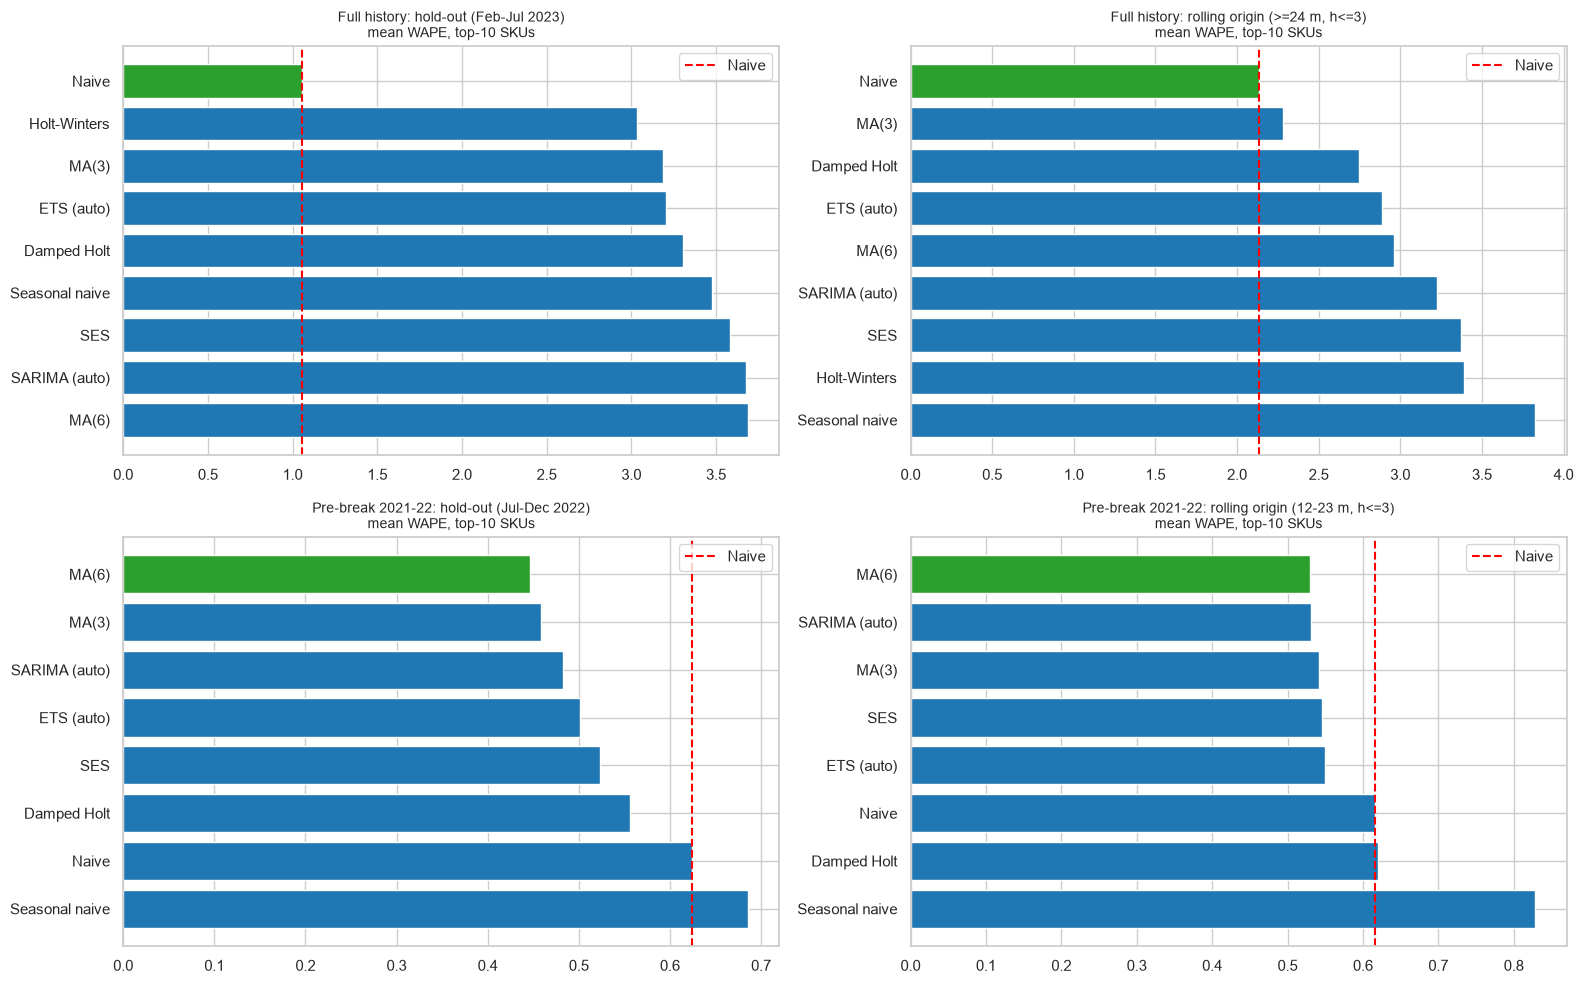

In [8]:
fig, axx = plt.subplots(2, 2, figsize=(16, 10)); ax = axx.ravel()
for a, s, t in zip(ax, [sum_hold, sum_roll, sum_pre_hold, sum_pre_roll],
                   ["Full history: hold-out (Feb-Jul 2023)", "Full history: rolling origin (>=24 m, h<=3)",
                    "Pre-break 2021-22: hold-out (Jul-Dec 2022)", "Pre-break 2021-22: rolling origin (12-23 m, h<=3)"]):
    s = s.dropna(subset=["WAPE_mean"]).sort_values("WAPE_mean")
    a.barh(s.index, s["WAPE_mean"], color=["tab:green" if i == s.index[0] else "tab:blue" for i in s.index])
    a.axvline(s.loc["Naive", "WAPE_mean"], color="red", ls="--", label="Naive")
    a.set_title(t + "\nmean WAPE, top-10 SKUs", fontsize=10); a.invert_yaxis(); a.legend()
plt.tight_layout(); plt.savefig(OUT / "02_model_comparison.png", dpi=130); plt.show()

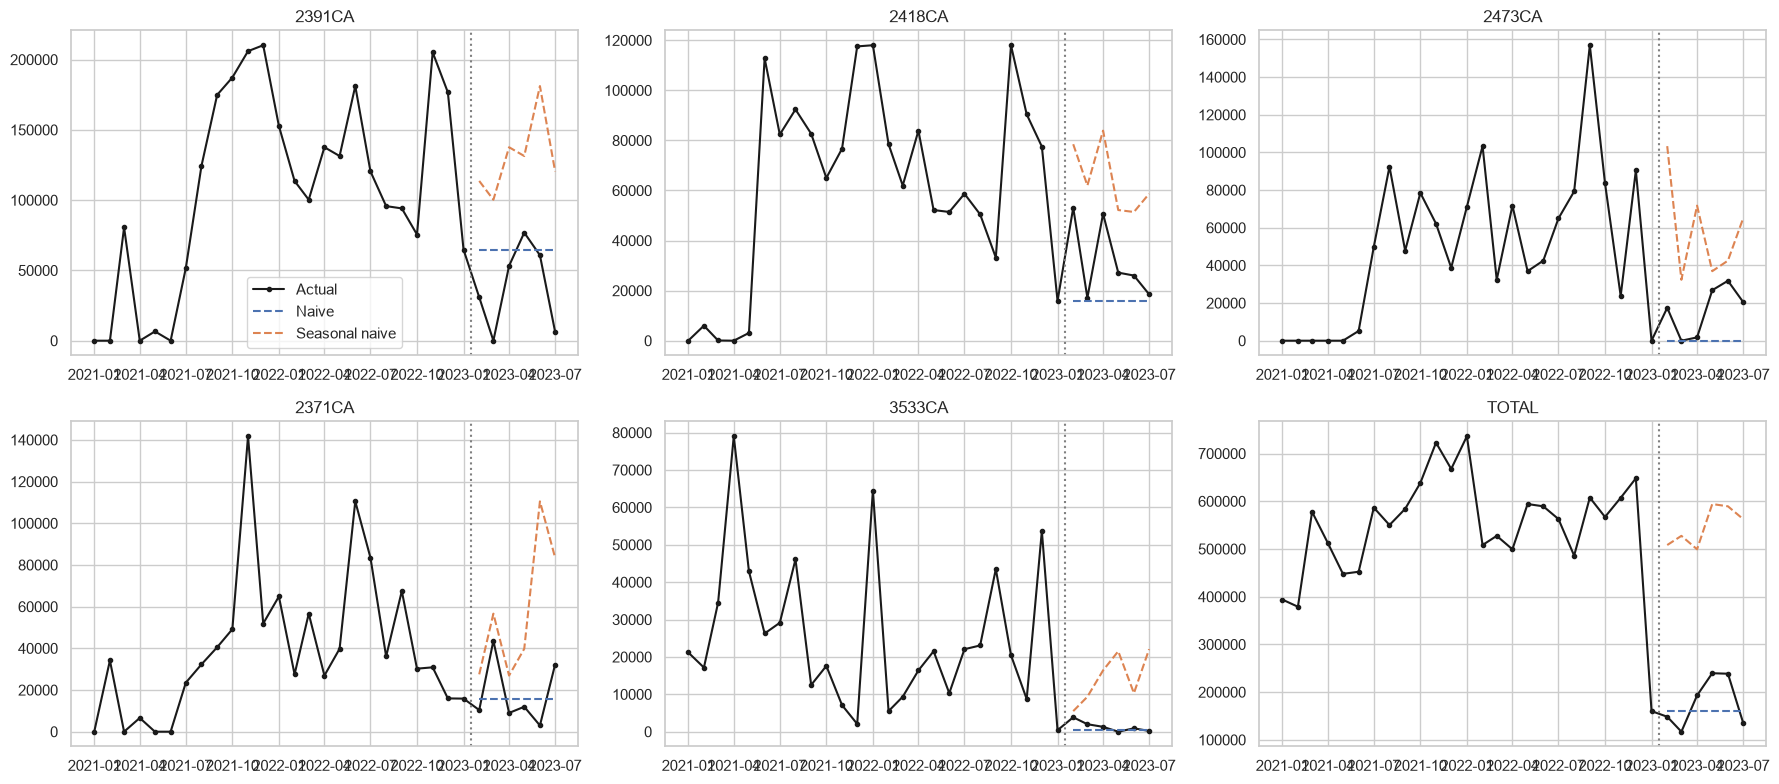

Best hold-out model (mean WAPE): Naive


In [9]:
# Forecast plots on the hold-out for the 4 biggest SKUs + total, for the best model, naive and seasonal naive
best_hold = sum_hold["WAPE_mean"].idxmin()
show = [m for m in dict.fromkeys(["Naive", "Seasonal naive", best_hold])]
fig, axes = plt.subplots(2, 3, figsize=(18, 8)); axes = axes.ravel()
for a, key in zip(axes, top10[:5] + ["TOTAL"]):
    a.plot(months, series[key], "k-o", ms=3, label="Actual")
    for m in show:
        g = hold[(hold.series == key) & (hold.model == m)].sort_values("t_idx")
        a.plot(g["month"], g["forecast"], "--", label=m)
    a.axvline(months[24] + pd.Timedelta(days=15), color="grey", ls=":")
    a.set_title(key)
axes[0].legend(); plt.tight_layout(); plt.savefig(OUT / "03_holdout_forecasts.png", dpi=130); plt.show()
print("Best hold-out model (mean WAPE):", best_hold)

## 5. From forecast error to safety stock
Classical safety stock: `SS = z * sigma * sqrt(L)`, with `z = 1.645` (95% cycle service level) and `L` the supplier lead time in months (`Average Lead Time (days) / 30.4`).

The only thing that changes between the approaches is **sigma**:
- **Demand-variability SS:** sigma = standard deviation of monthly demand over the whole history (the method used in project `python/02_inventory_optimization`). It inflates sigma with trend/level shifts that a forecast already explains.
- **Forecast-error SS:** sigma = RMSE of the one-step-ahead rolling-origin forecast errors of a given method (computed twice: on the full history incl. the 2023 shift, and on the stable 2021-22 regime) - the uncertainty the planner is really exposed to *after* forecasting.

Caveats: assumes forecast errors are independent across months and approximately normal (the sqrt(L) scaling), and sigma is estimated from only 12-19 one-step errors per SKU - indicative, not precise. Costs use `Cost per SKU` from the inventory sheet.

=== Full history incl. 2023 shift (rolling origins 12-30) | one-step errors per SKU: 19 ===


,Safety stock (units),Safety stock value ($),vs classical,vs naive-error
Demand std-dev (classical),566329.234,2697729.641,0.000,0.063
Naive forecast error,532727.787,2782299.998,-0.059,0.000
MA(3) forecast error,498029.790,2394344.784,-0.121,-0.065
SES forecast error,481029.654,2363873.369,-0.151,-0.097
ETS (auto) forecast error,478104.387,2377678.895,-0.156,-0.103


=== Pre-break regime 2021-22 (rolling origins 12-23) | one-step errors per SKU: 12 ===


,Safety stock (units),Safety stock value ($),vs classical,vs naive-error
Demand std-dev (classical),582867.599,2785192.247,0.000,0.024
Naive forecast error,569011.564,3059856.961,-0.024,0.000
MA(3) forecast error,514303.050,2448122.972,-0.118,-0.096
SES forecast error,499439.863,2471186.127,-0.143,-0.122
ETS (auto) forecast error,502545.000,2422392.527,-0.138,-0.117


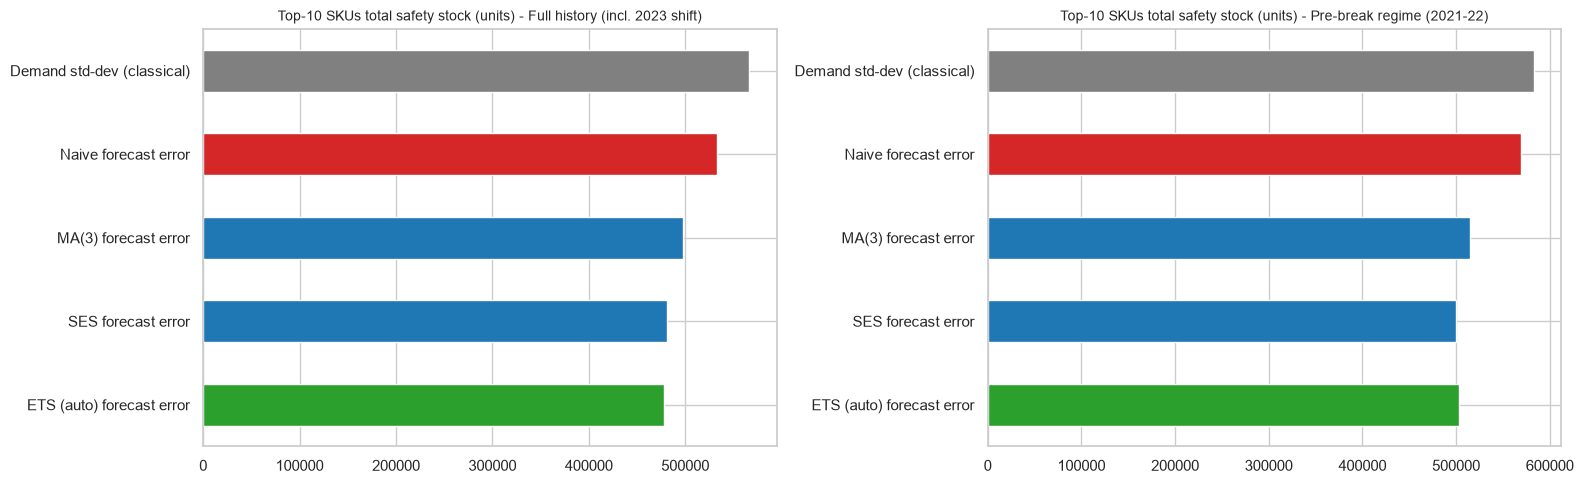

In [10]:
Z = 1.645
sku_info = inv.set_index("SKU ID").loc[top10, ["Vendor Name", "Average Lead Time (days)", "Cost per SKU"]]
sku_info["L_months"] = sku_info["Average Lead Time (days)"] / 30.4
SS_MODELS = ["Naive", "MA(3)", "SES", "ETS (auto)"]

def ss_table(h1_df, n_months, label):
    ss = sku_info.copy()
    ss["sigma_demand"] = [series[k][:n_months].std(ddof=1) for k in ss.index]
    for m in SS_MODELS:
        g = h1_df[h1_df.model == m].dropna(subset=["forecast"])
        ss["sigma_" + m] = g.groupby("series")["error"].apply(lambda e: np.sqrt((e ** 2).mean()))
    ss["n_errors"] = h1_df[h1_df.model == "Naive"].groupby("series").size()
    rows = {}
    for lab, col in [("Demand std-dev (classical)", "sigma_demand")] + [(f"{m} forecast error", "sigma_" + m) for m in SS_MODELS]:
        units = Z * ss[col] * np.sqrt(ss["L_months"])
        rows[lab] = (units.sum(), (units * ss["Cost per SKU"]).sum())
    out = pd.DataFrame(rows, index=["Safety stock (units)", "Safety stock value ($)"]).T
    out["vs classical"] = out["Safety stock (units)"] / out.iloc[0, 0] - 1
    out["vs naive-error"] = out["Safety stock (units)"] / out.loc["Naive forecast error", "Safety stock (units)"] - 1
    print(f"=== {label} | one-step errors per SKU: {int(ss['n_errors'].iloc[0])} ===")
    display(out.round(3))
    return ss, out

h1_full = fc[(fc.scheme == "rolling") & (fc.h == 1) & (fc.series != "TOTAL")]
h1_pre = fc[(fc.scheme == "pre_rolling") & (fc.h == 1) & (fc.series != "TOTAL")]
ss_full, out_full = ss_table(h1_full, 31, "Full history incl. 2023 shift (rolling origins 12-30)")
ss_pre, out_pre = ss_table(h1_pre, 24, "Pre-break regime 2021-22 (rolling origins 12-23)")
ss_full.round(1).to_csv(OUT / "safety_stock_by_sku_full.csv"); ss_pre.round(1).to_csv(OUT / "safety_stock_by_sku_prebreak.csv")
out_full.round(4).to_csv(OUT / "safety_stock_summary_full.csv"); out_pre.round(4).to_csv(OUT / "safety_stock_summary_prebreak.csv")

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
for a, o, t in zip(ax, [out_full, out_pre], ["Full history (incl. 2023 shift)", "Pre-break regime (2021-22)"]):
    o["Safety stock (units)"].plot.barh(ax=a, color=["grey", "tab:red", "tab:blue", "tab:blue", "tab:green"]); a.invert_yaxis()
    a.set_title("Top-10 SKUs total safety stock (units) - " + t, fontsize=10)
plt.tight_layout(); plt.savefig(OUT / "04_safety_stock_impact.png", dpi=130); plt.show()

## 6. Conclusions and limitations

**What the numbers say** (WAPE = sum of absolute errors / sum of actual demand; lower is better; reported as a mean over the 10 SKUs):

| Setting | Naive | Best non-naive | Seasonal naive | Holt-Winters |
|---|---|---|---|---|
| Full history, hold-out Feb-Jul 2023 | **1.05** | 3.04 (Holt-Winters) | 3.48 | 3.04 |
| Full history, rolling origin (>=24 m) | **2.14** | 2.28 (MA(3)) | 3.83 | 3.39 |
| Pre-break 2021-22, hold-out Jul-Dec 2022 | 0.62 | **0.45 (MA(6))** | 0.69 | n/a (<24 m) |
| Pre-break 2021-22, rolling origin | 0.62 | **0.53 (MA(6))**; SARIMA 0.53, MA(3) 0.54 | 0.83 | n/a (<24 m) |

1. **A level shift, not seasonality, dominates the error.** From January 2023 the order count drops from ~1,300 to ~360 per month (-73%). Every method that averages the past (MA, SES, Holt, ETS, SARIMA, Holt-Winters) keeps forecasting the old level and produces hold-out errors of roughly 3x actual demand (mean WAPE 3.0-3.7 vs 1.05 for the naive forecast, which re-anchors to the last value). The ranking in the full-history tests is therefore "who adapts fastest to the shift", and the Naive forecast wins. For the TOTAL series the hold-out WAPE is 25% (naive) vs 139% (ETS).
2. **In the stable 2021-22 regime smoothing beats naive, but only moderately.** MA(6), MA(3), SARIMA, SES and ETS reduce WAPE by 11-14% (rolling origin) and 16-28% (hold-out) vs naive. SKU-month demand is very noisy (lumpy B2B orders, up to 7 zero-demand months in the top-10 series), so even the best method has ~45-55% WAPE per SKU, while the aggregate TOTAL series is forecast at 7-12% WAPE.
3. **Seasonality could not be validated.** Seasonal naive is the worst or near-worst everywhere (WAPE 0.69-0.83 in the stable regime) and Holt-Winters / seasonal ETS / seasonal SARIMA need >= 24 months of training, so they could only be tested after the shift, where they are dominated by the level problem. With 31 months of data a seasonal pattern can neither be estimated robustly nor shown to exist.
4. **Safety stock impact (top-10 SKUs, 95% service, `z * sigma * sqrt(L)`)**: replacing the demand standard deviation by the RMSE of one-step forecast errors reduces total safety stock by 12-14% in units (stable regime: 582,868 -> 499,440 units with SES, 502,545 with ETS, 514,303 with MA(3)) and by 11-13% in value (classical $2.79M vs $2.42M with ETS). On the full history the reduction is 12-16% in units (566,329 -> 478,104 with ETS) and ~12% in value. Using **naive** forecast errors gives no benefit (-2% to -6% in units, and **+3% to +10% in value**), i.e. the saving comes from a forecast that actually filters noise, not from forecasting per se.

**Limitations**
- Only 31 months and 290 SKUs, a single supplier/regime shift, and no promotion, price or stock-out information: lost sales are not observable, so "demand" is orders shipped.
- The 2023 drop looks like a data property (fewer sampled orders) rather than a verified business event; I did not remove or correct it, I reported both the full-history and the pre-break evaluation instead.
- Safety-stock sigma is estimated from only 12-19 one-step errors per SKU, assumes independent normally distributed errors and a sqrt(L) scaling, and the demand/error comparison is in-sample for the evaluation window. Treat the 12-15% reductions as indicative; differences between SES, ETS and MA(3) are well inside the noise.
- Model hyper-parameters are fitted per origin (AICc selection for ETS/SARIMA) and no extra tuning was done on the test windows, but with such short series the ranking among the smoothing methods is not statistically separable (no significance test was run).
- Only univariate methods were tested. Lead-time demand is not modelled directly (monthly buckets vs lead times of 15-90 days), and intermittent-demand methods (Croston/SBA) were not tried although several SKUs have many zero months.

**Practical takeaway:** for these SKUs use a short moving average / exponential smoothing at the monthly level, re-anchor quickly after regime changes (monitor tracking signal), and size safety stock on forecast-error RMSE rather than raw demand variability; do not rely on seasonal models until 3+ years of history exist.